In [1]:
# ==============================================================
# LOCAL PROJECT SETUP (added during VS Code migration)
# Portable replacement for Google Colab / Google Drive mounting.
# All research code below this block is unchanged.
# ==============================================================
import sys as _sys
from pathlib import Path as _Path

def _locate_project_root():
    start = _Path.cwd().resolve()
    for candidate in [start] + list(start.parents):
        if (candidate / "src" / "ecg_qpain" / "paths.py").is_file():
            return candidate
    return start

PROJECT_ROOT = _locate_project_root()
_src = str(PROJECT_ROOT / "src")
if _src not in _sys.path:
    _sys.path.insert(0, _src)

from ecg_qpain.paths import (
    ROOT, BASE_DIR, PROJECT_DIR, DRIVE_DIR, MYDRIVE, MOUNT_POINT, mount_path,
    DATA_DIR, RAW_DIR, PROCESSED_DIR, MODELS_DIR, REPORTS_DIR,
    MITDB_DIR, NSTDB_DIR, MITDB_EXTRACTED, NSTDB_EXTRACTED,
    B2_DIR, B3_DIR, B4_DIR,
)
print("Local project root:", PROJECT_ROOT)
# ==============================================================

# (Colab Drive import removed - local execution)
import os

MOUNT_POINT = str(PROJECT_ROOT)

# (Colab mount check removed - local execution; project root is local)

BASE_DIR = str(PROJECT_ROOT)

PROCESSED_DIR = os.path.join(BASE_DIR, "data", "processed")
REPORT_DIR = os.path.join(BASE_DIR, "reports")
MODEL_DIR = os.path.join(BASE_DIR, "models")

os.makedirs(MODEL_DIR, exist_ok=True)

print("Google Drive mounted:", os.path.ismount(MOUNT_POINT))
print("Project directory exists:", os.path.exists(BASE_DIR))
print("Processed directory exists:", os.path.exists(PROCESSED_DIR))
print("Reports directory exists:", os.path.exists(REPORT_DIR))
print("Model directory:", MODEL_DIR)

Mounted at /content/gdrive_mount
Google Drive mounted: True
Project directory exists: True
Processed directory exists: True
Reports directory exists: True
Model directory: /content/gdrive_mount/MyDrive/ECG_QPAIN_2027/models


In [2]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score
)

import json
import random

SEED = 2027

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
GPU available: False
Libraries imported successfully!


In [3]:
# Load training dataset
train_data = np.load(
    os.path.join(PROCESSED_DIR, "train_beats.npz")
)

X_train = train_data["X"]
y_train = train_data["y"]

# Load validation dataset
val_data = np.load(
    os.path.join(PROCESSED_DIR, "validation_beats.npz")
)

X_val = val_data["X"]
y_val = val_data["y"]

print("Training data shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

print("Validation data shape:", X_val.shape)
print("Validation labels shape:", y_val.shape)

print("Training classes:", np.unique(y_train))
print("Validation classes:", np.unique(y_val))

Training data shape: (59720, 288)
Training labels shape: (59720,)
Validation data shape: (19530, 288)
Validation labels shape: (19530,)
Training classes: [0 1 2 3]
Validation classes: [0 1 2 3]


In [4]:
# Convert to float32
X_train = X_train.astype(np.float32)
X_val = X_val.astype(np.float32)

# Add channel dimension
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]

# Verify shapes
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)

print("Training data dtype:", X_train.dtype)
print("Validation data dtype:", X_val.dtype)

print("NaN in training:", np.isnan(X_train).sum())
print("NaN in validation:", np.isnan(X_val).sum())

X_train: (59720, 288, 1)
X_val: (19530, 288, 1)
Training data dtype: float32
Validation data dtype: float32
NaN in training: 0
NaN in validation: 0


In [5]:
class_names = ["N", "S", "V", "F"]

train_counts = pd.Series(y_train).value_counts().sort_index()
val_counts = pd.Series(y_val).value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Class": class_names,
    "Train": train_counts.values,
    "Validation": val_counts.values
})

print(class_distribution)

  Class  Train  Validation
0     N  53119       17533
1     S   1956         462
2     V   4225        1518
3     F    420          17


In [6]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class Weights:")

for cls, weight in class_weights.items():
    print(f"{class_names[cls]}: {weight:.4f}")

Class Weights:
N: 0.2811
S: 7.6329
V: 3.5337
F: 35.5476


In [7]:
BATCH_SIZE = 128
EPOCHS = 30
NUM_CLASSES = 4
INPUT_SHAPE = (288, 1)

print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Number of classes:", NUM_CLASSES)
print("Input shape:", INPUT_SHAPE)

Batch size: 128
Epochs: 30
Number of classes: 4
Input shape: (288, 1)


In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

In [9]:
def build_cnn_model():

    model = tf.keras.Sequential([

        tf.keras.layers.Input(shape=INPUT_SHAPE),

        tf.keras.layers.Conv1D(
            32, kernel_size=7,
            activation="relu",
            padding="same"
        ),

        tf.keras.layers.BatchNormalization(),

        tf.keras.layers.MaxPooling1D(pool_size=2),

        tf.keras.layers.Conv1D(
            64, kernel_size=5,
            activation="relu",
            padding="same"
        ),

        tf.keras.layers.BatchNormalization(),

        tf.keras.layers.MaxPooling1D(pool_size=2),

        tf.keras.layers.Conv1D(
            128, kernel_size=3,
            activation="relu",
            padding="same"
        ),

        tf.keras.layers.BatchNormalization(),

        tf.keras.layers.GlobalAveragePooling1D(),

        tf.keras.layers.Dense(128, activation="relu"),

        tf.keras.layers.Dropout(0.4),

        tf.keras.layers.Dense(
            NUM_CLASSES,
            activation="softmax"
        )

    ])

    return model


cnn_model = build_cnn_model()

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 288, 32)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 288, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 144, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 144, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 144, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 72, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 72, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 72, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,188 (207.77 KB)

 Trainable params: 52,740 (206.02 KB)

 Non-trainable params: 448 (1.75 KB)

In [10]:
cnn_history = cnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 77s 159ms/step - accuracy: 0.7279 - loss: 0.5731 - val_accuracy: 0.3691 - val_loss: 0.9651 - learning_rate: 0.0010
Epoch 2/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 74s 158ms/step - accuracy: 0.8706 - loss: 0.3675 - val_accuracy: 0.5599 - val_loss: 0.8966 - learning_rate: 0.0010
Epoch 3/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 73s 157ms/step - accuracy: 0.9000 - loss: 0.2875 - val_accuracy: 0.7760 - val_loss: 0.5524 - learning_rate: 0.0010
Epoch 4/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 71s 153ms/step - accuracy: 0.9084 - loss: 0.2456 - val_accuracy: 0.9124 - val_loss: 0.3213 - learning_rate: 0.0010
Epoch 5/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 83s 156ms/step - accuracy: 0.9208 - loss: 0.2204 - val_accuracy: 0.8484 - val_loss: 0.4668 - learning_rate: 0.0010
Epoch 6/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 77s 164ms/step - accuracy: 0.9267 - loss: 0.1957 - val_accuracy: 0.8635 - val_loss: 0.4560 - learning_rate: 0.0010
Epoch 7/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - accuracy: 0.93

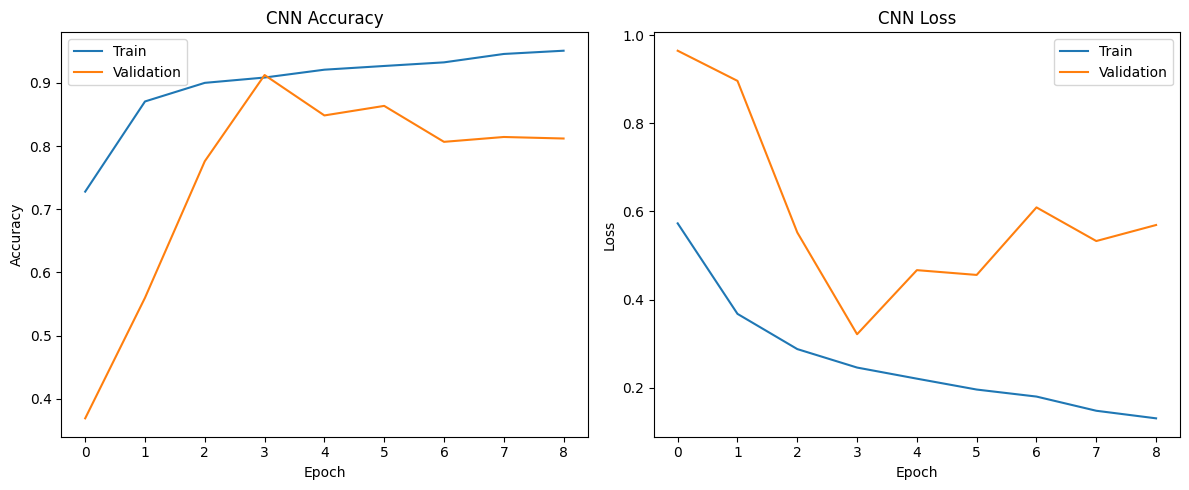

In [11]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(cnn_history.history["accuracy"], label="Train")
plt.plot(cnn_history.history["val_accuracy"], label="Validation")

plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(cnn_history.history["loss"], label="Train")
plt.plot(cnn_history.history["val_loss"], label="Validation")

plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [12]:
cnn_val_loss, cnn_val_accuracy = cnn_model.evaluate(
    X_val,
    y_val,
    verbose=1
)

cnn_predictions = cnn_model.predict(
    X_val,
    batch_size=BATCH_SIZE
)

cnn_pred_labels = np.argmax(cnn_predictions, axis=1)

cnn_macro_f1 = f1_score(
    y_val,
    cnn_pred_labels,
    average="macro",
    zero_division=0
)

print("CNN Validation Loss:", cnn_val_loss)
print("CNN Validation Accuracy:", cnn_val_accuracy)
print("CNN Validation Macro-F1:", cnn_macro_f1)

611/611 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.9124 - loss: 0.3213
153/153 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step
CNN Validation Loss: 0.3212587237358093
CNN Validation Accuracy: 0.912391185760498
CNN Validation Macro-F1: 0.4251103737697456


In [13]:
print(
    classification_report(
        y_val,
        cnn_pred_labels,
        labels=[0, 1, 2, 3],
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           N       0.96      0.97      0.96     17533
           S       0.02      0.00      0.01       462
           V       0.94      0.58      0.72      1518
           F       0.01      0.29      0.01        17

    accuracy                           0.91     19530
   macro avg       0.48      0.46      0.43     19530
weighted avg       0.94      0.91      0.92     19530



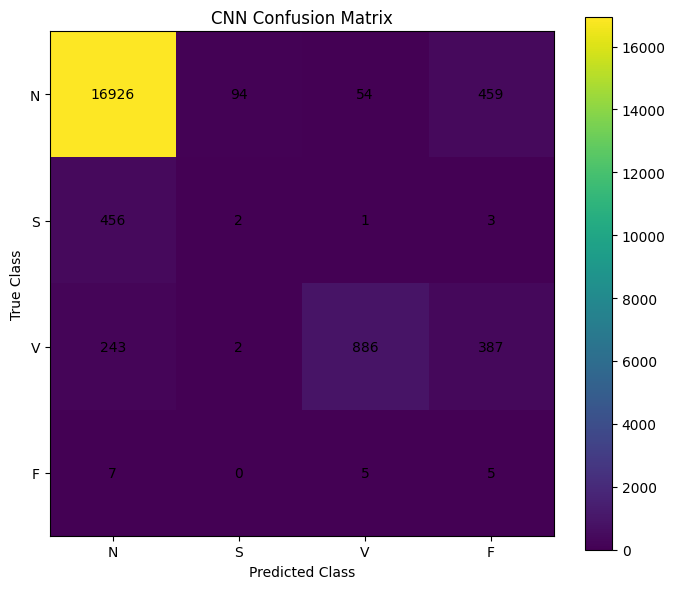

In [14]:
cnn_cm = confusion_matrix(
    y_val,
    cnn_pred_labels,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(7, 6))

plt.imshow(cnn_cm)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(range(4), class_names)
plt.yticks(range(4), class_names)

for i in range(4):
    for j in range(4):
        plt.text(j, i, cnn_cm[i, j],
                 ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

In [16]:
def residual_block(x, filters, kernel_size=5, stride=1):

    shortcut = x

    x = tf.keras.layers.Conv1D(
        filters,
        kernel_size,
        strides=stride,
        padding="same",
        use_bias=False
    )(x)

    x = tf.keras.layers.BatchNormalization()(x)

    x = tf.keras.layers.Activation("relu")(x)

    x = tf.keras.layers.Conv1D(
        filters,
        kernel_size,
        padding="same",
        use_bias=False
    )(x)

    x = tf.keras.layers.BatchNormalization()(x)

    if shortcut.shape[-1] != filters or stride != 1:

        shortcut = tf.keras.layers.Conv1D(
            filters,
            kernel_size=1,
            strides=stride,
            padding="same",
            use_bias=False
        )(shortcut)

        shortcut = tf.keras.layers.BatchNormalization()(shortcut)

    x = tf.keras.layers.Add()([x, shortcut])

    x = tf.keras.layers.Activation("relu")(x)

    return x

In [17]:
def build_resnet_model():

    inputs = tf.keras.layers.Input(shape=INPUT_SHAPE)

    x = tf.keras.layers.Conv1D(
        32,
        kernel_size=7,
        padding="same",
        use_bias=False
    )(inputs)

    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)

    x = residual_block(x, 32)
    x = residual_block(x, 64, stride=2)
    x = residual_block(x, 128, stride=2)

    x = tf.keras.layers.GlobalAveragePooling1D()(x)

    x = tf.keras.layers.Dense(128, activation="relu")(x)

    x = tf.keras.layers.Dropout(0.4)(x)

    outputs = tf.keras.layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = tf.keras.Model(inputs, outputs)

    return model


resnet_model = build_resnet_model()

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 288, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 288, 32)   │        224 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 288, 32)   │        128 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 288, 32)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 288, 32)   │      5,120 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 288, 32)   │        128 │ conv1d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 288, 32)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 288, 32)   │      5,120 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 288, 32)   │        128 │ conv1d_5[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 288, 32)   │          0 │ batch_normalizat… │
│                     │                   │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 288, 32)   │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 144, 64)   │     10,240 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 144, 64)   │        256 │ conv1d_6[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 144, 64)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 144, 64)   │     20,480 │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 144, 64)   │      2,048 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 144, 64)   │        256 │ conv1d_7[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 144, 64)   │        256 │ conv1d_8[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 144, 64)   │          0 │ batch_normalizat

 Total params: 194,020 (757.89 KB)

 Trainable params: 192,676 (752.64 KB)

 Non-trainable params: 1,344 (5.25 KB)

In [18]:
resnet_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

resnet_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

resnet_history = resnet_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[
        resnet_early_stopping,
        resnet_reduce_lr
    ],
    verbose=1
)

Epoch 1/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 281s 588ms/step - accuracy: 0.7787 - loss: 0.5608 - val_accuracy: 0.5981 - val_loss: 1.1251 - learning_rate: 0.0010
Epoch 2/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 332s 610ms/step - accuracy: 0.8892 - loss: 0.3535 - val_accuracy: 0.8228 - val_loss: 0.4472 - learning_rate: 0.0010
Epoch 3/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 279s 598ms/step - accuracy: 0.9034 - loss: 0.2904 - val_accuracy: 0.9448 - val_loss: 0.3067 - learning_rate: 0.0010
Epoch 4/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 281s 602ms/step - accuracy: 0.9119 - loss: 0.2608 - val_accuracy: 0.9019 - val_loss: 0.3827 - learning_rate: 0.0010
Epoch 5/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 282s 603ms/step - accuracy: 0.9232 - loss: 0.2206 - val_accuracy: 0.7955 - val_loss: 0.5328 - learning_rate: 0.0010
Epoch 6/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 563ms/step - accuracy: 0.9191 - loss: 0.2195
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
467/467 ━━━━━━━━━━━━━━━━━━━━ 281s 601ms/step - accuracy:

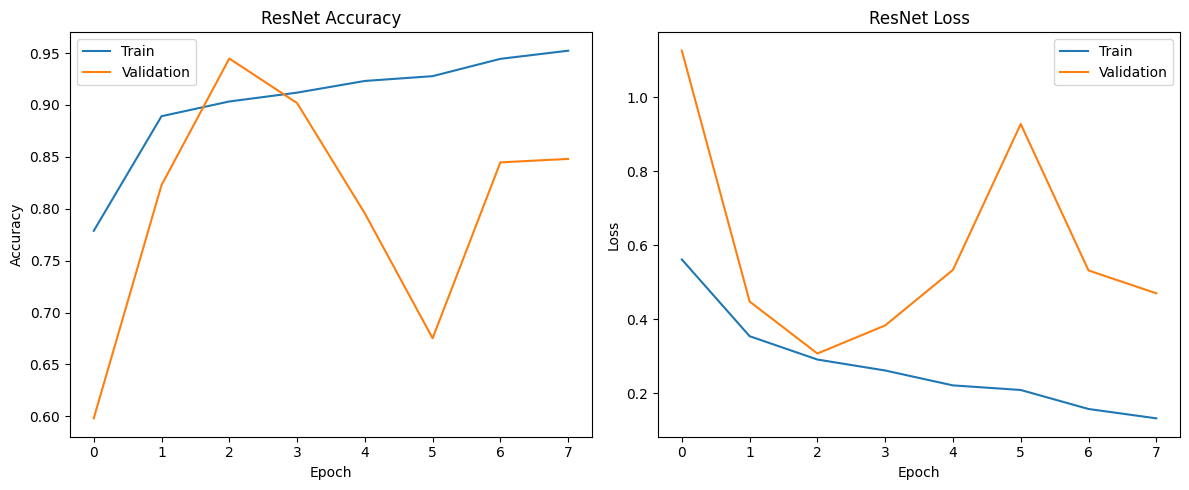

In [19]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(resnet_history.history["accuracy"], label="Train")
plt.plot(resnet_history.history["val_accuracy"], label="Validation")

plt.title("ResNet Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(resnet_history.history["loss"], label="Train")
plt.plot(resnet_history.history["val_loss"], label="Validation")

plt.title("ResNet Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [20]:
resnet_val_loss, resnet_val_accuracy = resnet_model.evaluate(
    X_val,
    y_val,
    verbose=1
)

resnet_predictions = resnet_model.predict(
    X_val,
    batch_size=BATCH_SIZE
)

resnet_pred_labels = np.argmax(resnet_predictions, axis=1)

resnet_macro_f1 = f1_score(
    y_val,
    resnet_pred_labels,
    average="macro",
    zero_division=0
)

print("ResNet Validation Loss:", resnet_val_loss)
print("ResNet Validation Accuracy:", resnet_val_accuracy)
print("ResNet Validation Macro-F1:", resnet_macro_f1)

611/611 ━━━━━━━━━━━━━━━━━━━━ 28s 46ms/step - accuracy: 0.9448 - loss: 0.3067
153/153 ━━━━━━━━━━━━━━━━━━━━ 19s 121ms/step
ResNet Validation Loss: 0.3066961169242859
ResNet Validation Accuracy: 0.9447516798973083
ResNet Validation Macro-F1: 0.45950803237390186


In [21]:
print(
    classification_report(
        y_val,
        resnet_pred_labels,
        labels=[0, 1, 2, 3],
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           N       0.97      0.98      0.97     17533
           S       0.02      0.00      0.00       462
           V       0.93      0.80      0.86      1518
           F       0.00      0.00      0.00        17

    accuracy                           0.94     19530
   macro avg       0.48      0.45      0.46     19530
weighted avg       0.94      0.94      0.94     19530



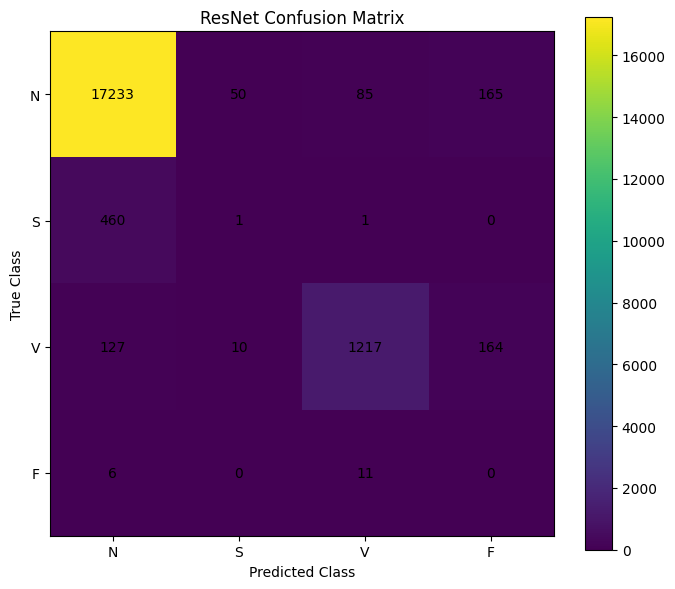

In [22]:
resnet_cm = confusion_matrix(
    y_val,
    resnet_pred_labels,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(7, 6))

plt.imshow(resnet_cm)

plt.title("ResNet Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(range(4), class_names)
plt.yticks(range(4), class_names)

for i in range(4):
    for j in range(4):
        plt.text(j, i, resnet_cm[i, j],
                 ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

In [23]:
cnn_path = os.path.join(MODEL_DIR, "B0_CNN_Clean.keras")
resnet_path = os.path.join(MODEL_DIR, "B1_ResNet_Clean.keras")

cnn_model.save(cnn_path)
resnet_model.save(resnet_path)

print("CNN model saved:", os.path.exists(cnn_path))
print("ResNet model saved:", os.path.exists(resnet_path))

CNN model saved: True
ResNet model saved: True


In [24]:
baseline_results = pd.DataFrame([
    {
        "Model": "B0_CNN",
        "Validation_Loss": float(cnn_val_loss),
        "Validation_Accuracy": float(cnn_val_accuracy),
        "Validation_Macro_F1": float(cnn_macro_f1)
    },
    {
        "Model": "B1_ResNet",
        "Validation_Loss": float(resnet_val_loss),
        "Validation_Accuracy": float(resnet_val_accuracy),
        "Validation_Macro_F1": float(resnet_macro_f1)
    }
])

results_path = os.path.join(
    REPORT_DIR,
    "clean_baseline_validation_results.csv"
)

baseline_results.to_csv(results_path, index=False)

print(baseline_results)
print("\nResults saved:", results_path)

       Model  Validation_Loss  Validation_Accuracy  Validation_Macro_F1
0     B0_CNN         0.321259             0.912391             0.425110
1  B1_ResNet         0.306696             0.944752             0.459508

Results saved: /content/gdrive_mount/MyDrive/ECG_QPAIN_2027/reports/clean_baseline_validation_results.csv


In [25]:
training_config = {
    "seed": SEED,
    "input_shape": list(INPUT_SHAPE),
    "num_classes": NUM_CLASSES,
    "class_names": class_names,
    "batch_size": BATCH_SIZE,
    "maximum_epochs": EPOCHS,
    "optimizer": "Adam",
    "initial_learning_rate": 0.001,
    "loss": "sparse_categorical_crossentropy",
    "class_weighting": "balanced",
    "early_stopping_patience": 5,
    "models": ["B0_CNN", "B1_ResNet"],
    "test_set_used": False
}

training_config_path = os.path.join(
    REPORT_DIR,
    "clean_baseline_training_config.json"
)

with open(training_config_path, "w") as f:
    json.dump(training_config, f, indent=4)

print("Training configuration saved!")
print(training_config_path)

Training configuration saved!
/content/gdrive_mount/MyDrive/ECG_QPAIN_2027/reports/clean_baseline_training_config.json


In [26]:
assert os.path.exists(cnn_path)
assert os.path.exists(resnet_path)
assert os.path.exists(results_path)
assert os.path.exists(training_config_path)

assert X_train.shape[1:] == (288, 1)
assert X_val.shape[1:] == (288, 1)

assert len(np.unique(y_train)) == 4
assert len(np.unique(y_val)) == 4

print("CNN model: OK")
print("ResNet model: OK")
print("Validation results: OK")
print("Training configuration: OK")
print("Test dataset untouched: OK")

print("\nNOTEBOOK 05 BASELINE PIPELINE COMPLETED!")

CNN model: OK
ResNet model: OK
Validation results: OK
Training configuration: OK
Test dataset untouched: OK

NOTEBOOK 05 BASELINE PIPELINE COMPLETED!
